# Pipelines: one call, one folder

> **Install:** this tutorial needs the `pipeline` extra: `pip install "virgil-astro[pipeline]"`.

The other tutorials build an analysis one step at a time, which is how you learn it. Once you know the steps, you will want to run them the same way on every target and come back to the results a month later without rerunning anything. That is what a *pipeline* is for: a fixed sequence of named stages that each write their outputs into a run folder, finish with quality checks, and can be reloaded in a fresh session.

A pipeline adds no science. Every number it reports comes from a public virgil function that you can call yourself, as the "As a pipeline" sections of the [binary search](binary_search.md), [contrast limits](contrast_limits.md) and [limb darkening](limb_darkening.md) tutorials show. This page is about the machinery around those functions. We use the smallest problem that shows all of it: a simulated companion around a star, seen through a seven-hole aperture mask.

In [1]:
import os
import shutil
import warnings

# Silence zodiax's docstring SyntaxWarning here and in the subprocesses the cells below start.
os.environ["PYTHONWARNINGS"] = "ignore::SyntaxWarning"
warnings.filterwarnings("ignore", category=SyntaxWarning)
warnings.filterwarnings("ignore", message="IProgress not found")

import json
import subprocess
import sys
from pathlib import Path

import jax
import numpy as onp
from IPython.display import Image, display

from virgil.coverage import nrm_oidata
from virgil.models import BinaryModelCartesian
from virgil.pipeline import BinaryPipeline, ConfigMismatchError, load

work = Path("pipeline_demo")  # a fixed folder, recreated on every run
shutil.rmtree(work, ignore_errors=True)

## Simulate a binary

[`nrm_oidata`](api/coverage.md) gives the uv coverage of the NIRISS aperture mask with zero data, and `with_model` fills it from a model with Gaussian noise. Here the companion is 3% as bright as the star, about 117 mas away to the south-east.

In [2]:
truth = BinaryModelCartesian(dra=100.0, ddec=-60.0, flux=0.03)
data = nrm_oidata().with_model(truth, key=jax.random.PRNGKey(0))
print(data.vis.size, "squared visibilities and", data.phi.size, "closure phases")

21 squared visibilities and 35 closure phases


## Run it

A pipeline takes the data, a model template (its class sets the parameterization of the answer; the fit starts from the grid search's best point, so the template's values need no tuning), a run folder and keyword settings. We keep the sampler short with `num_warmup`, `num_samples` and `num_chains` so that the whole run takes a minute or so. A seven-hole mask has its holes on a triangular lattice, so its visibilities and closure phases cannot tell a companion from one displaced by a lattice vector, and the nearest of these are 776 mas away. On such coverage the default search grid is limited to 336 mas, half the smallest larger coordinate of an alias vector (672 mas), so that no two points of the square differ by a lattice vector; the summary records the limit as `search.alias_cap_mas`. We also set `flux_range` and `n_flux`: with the default flux axis the likelihood peak of this companion falls between grid points and the pipeline warns that the Bayes factor is inaccurate, so we give it 1000 points between $10^{-4}$ and 1, a range that brackets the 3% companion. Every other setting is the default.

In [3]:
template = BinaryModelCartesian(dra=0.0, ddec=0.0, flux=1e-3)

res = BinaryPipeline(
    data,
    template,
    output=work / "binary_run",
    num_warmup=500,
    num_samples=500,
    num_chains=2,
    flux_range=[1e-4, 1.0],
    n_flux=1000,
).run()
res.status

'complete'

## The run folder

Everything the run produced is in `output`, as JSON, HDF5, NumPy, PNG and OIFITS files, with no pickles. Here is the layout (the files inside each stage's folder are left out):

In [4]:
for p in sorted(res.path.rglob("*")):
    rel = p.relative_to(res.path)
    if len(rel.parts) <= 2:
        print(f"{'  ' * (len(rel.parts) - 1)}{rel.name}{'/' if p.is_dir() else ''}")

data/
  processed.oifits
grids.h5
models/
  best/
plots/
  fit_correlation.png
  limits_contrast_curve.png
  limits_map.png
  overview_data.png
  overview_uv.png
  posterior_corner.png
  posterior_trace.png
  search_delta_chi2.png
  search_snr.png
quicklook.ipynb
quicklook.log
run.json
samples.h5
stages/
  fit/
  limits/
  load/
  overview/
  posterior/
  quicklook/
  search/
summary.json


`run.json` records the resolved settings, the sha256 of the inputs, the versions of the libraries, and the status and timings of each stage. `summary.json` holds the key numbers and the checks. `plots/` has the figures, and `quicklook.ipynb` is an executed notebook that reloads the folder and shows them, so a collaborator can open the results without installing anything beyond Jupyter.

## Reading the results

`res` is a `Result`. Its `summary` is a plain dictionary of numbers by section, so you can pull out whatever you need:

In [5]:
comp = res.summary["companion"]
print(f"fitted: {comp['sep_mas']:.1f} mas, PA {comp['pa_deg']:.1f} deg")
print(f"truth:  {(100.0**2 + 60.0**2) ** 0.5:.1f} mas, PA {onp.degrees(onp.arctan2(100.0, -60.0)):.1f} deg")

fitted: 117.1 mas, PA 118.8 deg
truth:  116.6 mas, PA 121.0 deg


`describe()` prints the key numbers, the checks and a count of any warnings raised inside the stages in one block. Look at the checks first. The first is always the $\chi^2$ per independent datum on the *quoted* errors, because a fitted error scale makes $\chi^2$ close to one by construction and tells you nothing.

In [6]:
print(res.describe())

BinaryPipeline run in pipeline_demo/binary_run: complete
  data.n_vis = 21
  data.n_phi = 35
  data.n_independent = 36
  data.wavel_min_m = 4.3e-06
  data.wavel_max_m = 4.3e-06
  data.baseline_min_m = 1.32
  data.baseline_max_m = 5.28001
  data.resolution_mas = 83.9903
  data.fov_mas = 671.923
  chi2.n_independent = 36
  chi2.null_reduced = 45.0561
  chi2.companion_reduced = 1.01297
  search.delta_chi2 = 1508.68
  search.log_bayes_factor = 743.643
  search.max_snr = 37.1675
  search.local_nsigma = 12.95
  search.global_nsigma = 3.09053
  search.false_alarm_probability = 0.000999001
  search.n_null = 1000
  search.n_null_above = 0
  search.dra_mas = 111.987
  search.ddec_mas = -74.6581
  search.flux = 0.0292057
  search.max_sep_mas = 335.962
  search.alias_cap_mas = 335.962
  limits.sigma = 3
  limits.deepest_delta_mag = 4.29645
  fit.chi2_reduced = 1.01297
  companion.sep_mas = 117.123
  companion.pa_deg = 118.822
  companion.dra_mas = 102.614
  companion.ddec_mas = -56.464
  companion

`res.checks` has the same checks as objects with `name`, `status` (`pass`, `warn` or `fail`), `value`, `threshold` and `message`, which is what you want in a script that has to decide whether to trust a run:

In [7]:
[(c.name, c.status) for c in res.checks]

[('chi2', 'pass'),
 ('detection', 'pass'),
 ('grid_edge', 'pass'),
 ('residual_normality', 'pass'),
 ('field_of_view', 'pass'),
 ('prior_bound', 'pass'),
 ('r_hat', 'pass'),
 ('ess', 'pass'),
 ('divergences', 'pass'),
 ('convergence', 'warn'),
 ('stage_warnings', 'warn')]

Any `warn` here is a caution, not a failure. The `convergence` and `stage_warnings` entries say that the flux refinement did not converge at a small fraction of the grid positions (the check message in the report above gives the count), so those pixels of the limits map are NaN. This is a caution about the limits, not about the fit. The run sets `n_flux` high enough that the flux axis resolves the likelihood peak; with the default it would add a `flux_axis_resolution` warning.

The figures live in `res.plots`. This is the contrast curve from the `limits` stage: the faintest companion the data could have shown at each separation.

['fit_correlation.png', 'limits_contrast_curve.png', 'limits_map.png', 'overview_data.png', 'overview_uv.png', 'posterior_corner.png', 'posterior_trace.png', 'search_delta_chi2.png', 'search_snr.png']


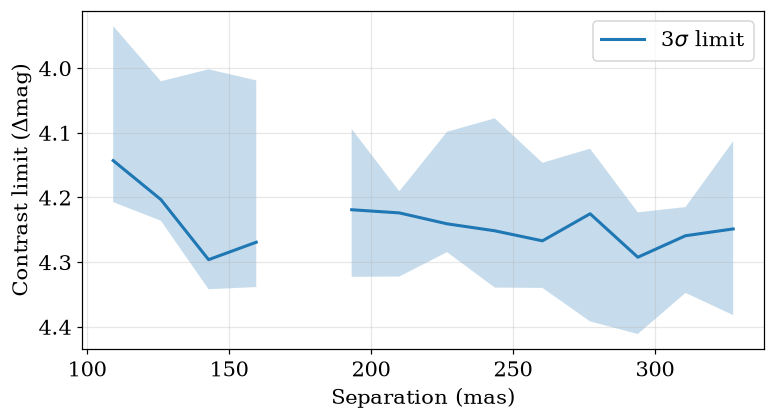

In [8]:
print([p.name for p in res.plots])
display(Image(filename=str(res.path / "plots" / "limits_contrast_curve.png")))

## Loading a run instead of rerunning it

In a fresh session, point `load` at the folder. Nothing is recomputed: each accessor reads the files the run wrote.

In [9]:
again = load(res.path)
model = again.model()  # the best-fit model, a real virgil object
print(type(model).__name__, model.dra, model.ddec, model.flux)
print(again.samples()["dra"].shape)  # (chain, draw)

BinaryModelCartesian 102.51669 -56.45 0.030073004
(2, 500)


`data()` returns the data as fitted, `fit_result()` the maximum-likelihood fit (to continue with [`fit`](api/fitting.md)), and `grid()` the search maps. The [pipeline page](pipeline.md) lists every accessor.

## Stopping early and resuming

A non-detection does not need a fit or a sampler. `run(through="limits")` stops after the named stage, and the run is then `partial`. Here is a fresh folder for the same data, run through the contrast limits only:

In [10]:
short = BinaryPipeline(
    data, template, output=work / "short_run",
    num_warmup=500, num_samples=500, num_chains=2,
)
res2 = short.run(through="limits")
print(res2.status)
print({name: s["status"] for name, s in res2.run["stages"].items()})

partial
{'load': 'complete', 'overview': 'complete', 'search': 'complete', 'limits': 'complete'}


Run it again without `through` and it carries on from where it stopped. A stage that completed, with its outputs still on disk, is skipped. Once a stage reruns, every later stage reruns too, since they depend on it.

In [11]:
started = {name: s["started"] for name, s in res2.run["stages"].items()}
res2 = short.run()
for name, s in res2.run["stages"].items():
    print(f"{name:10s} {'skipped' if started.get(name) == s['started'] else 'ran'}")
print(res2.status)

load       skipped
overview   skipped
search     skipped
limits     skipped
fit        ran
posterior  ran
quicklook  ran
complete


A resumed run refuses to continue if anything it depends on has changed: the settings, the data or the model template. Without this you could mix the stages of two different analyses in one folder, and the summary would describe neither.

In [12]:
changed = BinaryPipeline(
    data, template, output=work / "short_run",
    num_warmup=500, num_samples=500, num_chains=2, sigma=5.0,
)
try:
    changed.run()
except ConfigMismatchError as err:
    print(err)

pipeline_demo/short_run holds a run with a different configuration (sigma: stored 3.0, now 5.0). Use a new output folder, or run(resume=False) to start this one over.


The message names each difference. Either use a new folder, or start this one over with `run(resume=False)`.

## Settings

Settings resolve in three layers, and each overrides the one before: the class defaults, then a JSON config file, then keyword arguments. `defaults()` shows what you can set:

In [13]:
BinaryPipeline.defaults()

{'sigma': 3.0,
 'detection_sigma': 3.0,
 'n_null': 1000,
 'max_sep_mas': None,
 'fov_fraction': 1.0,
 'grid_step_mas': None,
 'max_grid': 101,
 'flux_range': [1e-05, 1.0],
 'n_flux': 40,
 'wavel_range': None,
 'error_floor': None,
 'error_scale': 'quoted',
 'num_warmup': 1000,
 'num_samples': 1000,
 'num_chains': 4,
 'chain_method': 'vectorized',
 'seed': 0,
 'batch_size': None,
 'limit_bins': 20,
 'limit_method': 'ruffio',
 'quicklook_execute': True}

A typo raises a `TypeError` that lists the valid names. For a config file, give the data (OIFITS paths, relative to the file), the run folder and any settings. We reuse the data the first run fitted, which it wrote as `data/processed.oifits`, so the config reads a real file:

In [14]:
config = work / "config.json"
config.write_text(json.dumps({
    "data": ["binary_run/data/processed.oifits"],  # relative to this file
    "output": "config_run",
    "settings": {"num_warmup": 500, "num_samples": 500, "num_chains": 2, "sigma": 2.0},
}, indent=2))

p = BinaryPipeline.from_config(config, template, sigma=4.0)  # keywords win
print(p.settings["sigma"], p.settings["num_chains"])
p.run(through="load")  # cheap: writes run.json with the resolved settings
print(load(p.output).run["config"]["sigma"])

4.0 2
4.0


The config file says `sigma` is 2, the keyword says 4, and the keyword wins; `num_chains` comes from the file; everything else is a default. The resolved settings are written to `run.json`, so the folder records what was actually used.

## From the command line

Everything above is also available from a shell as `virgil-pipeline`, which is convenient for batch jobs and for running over many OIFITS files:

```bash
virgil-pipeline binary hd1234.oifits -o runs/hd1234 --set sigma=3 --set num_chains=2
virgil-pipeline binary hd1234.oifits -o runs/hd1234 --through limits --fresh
virgil-pipeline info runs/hd1234        # status and checks
virgil-pipeline validate runs/hd1234    # complete, and every file matches its hash
virgil-pipeline quicklook runs/hd1234   # rebuild the quicklook notebook
```

`--set KEY=VALUE` overrides a setting, `--fresh` starts over, and `info` and `validate` only read JSON and hashes. Here is the same thing on our run, called from the notebook:

In [15]:
def cli(*args):
    out = subprocess.run(
        [sys.executable, "-m", "virgil.pipeline.cli", *map(str, args)],
        capture_output=True, text=True,
    )
    print(out.stdout + out.stderr)
    if out.returncode:
        raise RuntimeError(f"virgil-pipeline exited with {out.returncode}")

cli("info", res.path)
cli("validate", res.path)

BinaryPipeline (provisional), schema virgil-pipeline-run-v1
status: complete
  load       complete       0.4 s
  overview   complete       1.4 s
  search     complete     129.9 s
  limits     complete       2.0 s
  fit        complete       3.2 s
  posterior  complete      13.1 s
  quicklook  complete      13.6 s
  [pass] chi2: χ²/N = 1.01 for the best-fit binary (star alone: 45.1) on quoted errors: consistent with the quoted errors.
  [pass] detection: Companion detected at ≥3.09σ against simulated companion-free searches (12.95σ local).
  [pass] grid_edge: The grid peak lies inside the searched grid.
  [pass] residual_normality: Whitened residuals look normal (skew -0.21, excess kurtosis -1.11).
  [pass] field_of_view: Separation 117 mas lies between the resolution limit and the field of view.
  [pass] prior_bound: No posterior mass piles up at a prior bound.
  [pass] r_hat: Largest R-hat 1.0048: the chains agree.
  [pass] ess: Smallest bulk ESS 723: enough independent samples.
  [pa

valid: BinaryPipeline run, status complete



In [16]:
cli(
    "binary", res.path / "data" / "processed.oifits",
    "-o", work / "cli_run", "--through", "limits",
    "--set", "sigma=3", "--set", "n_flux=20",
)
cli("info", work / "cli_run")

BinaryPipeline run in pipeline_demo/cli_run: partial
  data.n_vis = 21
  data.n_phi = 35
  data.n_independent = 36
  data.wavel_min_m = 4.3e-06
  data.wavel_max_m = 4.3e-06
  data.baseline_min_m = 1.32
  data.baseline_max_m = 5.28001
  data.resolution_mas = 83.9903
  data.fov_mas = 671.923
  chi2.n_independent = 36
  chi2.null_reduced = 45.0561
  search.delta_chi2 = 1508.68
  search.log_bayes_factor = 739.033
  search.max_snr = 37.1675
  search.local_nsigma = 12.95
  search.global_nsigma = 3.09053
  search.false_alarm_probability = 0.000999001
  search.n_null = 1000
  search.n_null_above = 0
  search.dra_mas = 111.987
  search.ddec_mas = -74.6581
  search.flux = 0.0292057
  search.max_sep_mas = 335.962
  search.alias_cap_mas = 335.962
  limits.sigma = 3
  limits.deepest_delta_mag = 4.29707
  [fail] chi2: χ²/N = 45.1 for the star alone on quoted errors: the model does not describe the data, or the errors are much too small.
  [pass] detection: Companion detected at ≥3.09σ against simula

BinaryPipeline (provisional), schema virgil-pipeline-run-v1
status: partial
  load       complete       0.6 s
  overview   complete       2.5 s
  search     complete      76.7 s
  limits     complete       2.0 s
  [fail] chi2: χ²/N = 45.1 for the star alone on quoted errors: the model does not describe the data, or the errors are much too small.
  [pass] detection: Companion detected at ≥3.09σ against simulated companion-free searches (12.95σ local).
  [pass] grid_edge: The grid peak lies inside the searched grid.
  [warn] convergence: The optimizer did not converge at 2 of 361 grid positions (0.55 per cent): values there may be inaccurate.
  [warn] flux_axis_resolution: The flux axis does not resolve the likelihood peak (0.084 steps across its FWHM): log_bayes_factor is inaccurate; use a finer flux axis (n_flux).
  [warn] stage_warnings: 1 warning(s) were raised inside the stages: ruffio limits: 2 of 361 grid positions have an unconverged flux refinement or no finite Laplace sigma; th

The `chi2` check fails here, as it should: the run stops at `limits`, so no companion was fitted and the only $\chi^2/N$ is that of the star alone. The `flux_axis_resolution` warning is there because this call sets `n_flux=20` to keep it quick, which is too coarse to resolve the flux peak.

## Where next

The [pipeline page](pipeline.md) lists the stages and the checks, and the [`StarPipeline`](pipeline.md#starpipeline-stellar-diameters) and [`DiskPipeline`](pipeline.md#diskpipeline-rings-and-haloes-provisional) work the same way. Because every number comes from a public function, you can always take a run apart: `res.model()` and `res.data()` give you the objects to carry on with by hand.